# Experiment 06: Reinforcement Learning in a Maze Environment
**Aim:** Implement Q-Learning algorithm in a grid-world maze environment to train an autonomous agent to find the optimal shortest path.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 1. Setup Maze Environment Parameters
size = 6
walls = {(1, 1), (1, 2), (1, 4), (2, 4), (3, 1), (3, 2), (4, 2), (4, 4)}
start = (0, 0)
goal = (size - 1, size - 1)
actions = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # 0: Up, 1: Down, 2: Left, 3: Right
action_names = ['Up', 'Down', 'Left', 'Right']

# Initialize Q-Table
Q = np.zeros((size * size, 4))
alpha = 0.1      # Learning rate
gamma = 0.95     # Discount factor
eps = 1.0        # Initial exploration rate

In [6]:
# 2. Train Agent with Q-Learning (500 episodes)
np.random.seed(42)
for ep in range(500):
    r, c = start
    for _ in range(100):
        s = r * size + c
        a = np.random.randint(4) if np.random.rand() < eps else np.argmax(Q[s])
        nr, nc = r + actions[a][0], c + actions[a][1]

        # Check collision with walls or boundaries
        if nr < 0 or nr >= size or nc < 0 or nc >= size or (nr, nc) in walls:
            # Hit wall or out of bounds: agent stays in place, gets penalty
            reward, ns, done = -10, s, False
        elif (nr, nc) == goal:
            # Goal reached
            reward, ns, done = 100, nr * size + nc, True
            r, c = nr, nc
        else:
            # Normal valid step
            reward, ns, done = -1, nr * size + nc, False
            r, c = nr, nc

        # Q-Learning Bellman Update
        Q[s, a] += alpha * (reward + gamma * np.max(Q[ns]) - Q[s, a])
        if done:
            break
    eps = max(0.05, eps * 0.992)

print('Q-Learning Training Complete! Final Epsilon:', round(eps, 4))

Q-Learning Training Complete! Final Epsilon: 0.05


Optimal Path Successfully Found! Length: 10 steps
Path: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (2, 3), (3, 3), (3, 4), (3, 5), (4, 5), (5, 5)]


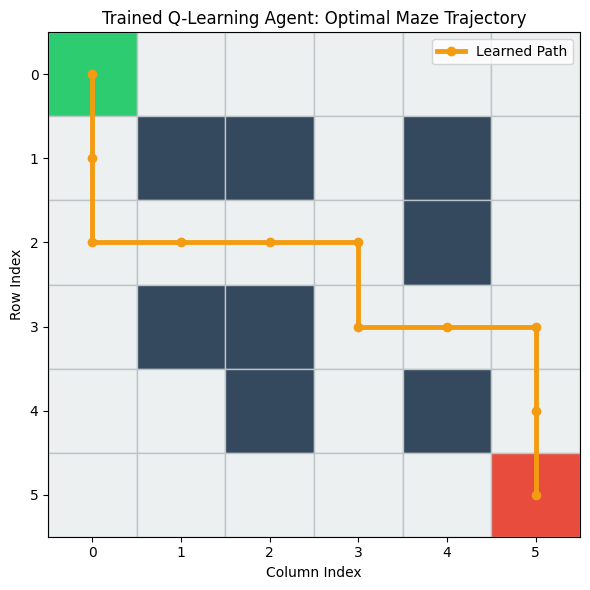

In [7]:
# 3. Extract Learned Optimal Path & Visualize
pos, path = start, [start]
visited = {start}
while pos != goal and len(path) < 25:
    s = pos[0] * size + pos[1]
    a = np.argmax(Q[s])
    next_pos = (pos[0] + actions[a][0], pos[1] + actions[a][1])
    if next_pos[0] < 0 or next_pos[0] >= size or next_pos[1] < 0 or next_pos[1] >= size or next_pos in walls or next_pos in visited:
        break
    pos = next_pos
    path.append(pos)
    visited.add(pos)

print(f'Optimal Path Successfully Found! Length: {len(path) - 1} steps')
print('Path:', path)

# Visual Maze Plot with Path Overlay
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-0.5, size - 0.5)
ax.set_ylim(-0.5, size - 0.5)
ax.invert_yaxis()

for r in range(size):
    for c in range(size):
        color = '#2ecc71' if (r, c) == start else ('#e74c3c' if (r, c) == goal else ('#34495e' if (r, c) in walls else '#ecf0f1'))
        ax.add_patch(patches.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor=color, edgecolor='#bdc3c7'))

path_c = [p[1] for p in path]
path_r = [p[0] for p in path]
ax.plot(path_c, path_r, color='#f39c12', linewidth=3.5, marker='o', label='Learned Path')
plt.title('Trained Q-Learning Agent: Optimal Maze Trajectory')
plt.xlabel('Column Index')
plt.ylabel('Row Index')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()